
# **RMAVD: A Repository-Level Multi-Agent Framework for Software Vulnerability Detection**

**Author:** Amal

**Table of Contents**

| Part | Section |
|:---:|---|
| **Part 1** | Environment Setup
| **Part 2** | Dataset Exploration and Preparation
| **Part 3** | Multi-Agent Framework Implementation
| **Part 4** | Experimental Execution
| **Part 5** | Evaluation and Results
| **Part 6** | Streamlit Application


## **Part 1: Environment Setup**

**Install Ollama and Pull the Model**



In [1]:
!apt-get update -qq
!apt-get install -y zstd
!curl -fsSL https://ollama.com/install.sh | sh
!pip install -q ollama datasets pandas numpy matplotlib gitpython requests streamlit

import subprocess, time, requests

ollama_process = subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)
print("Ollama status:", requests.get("http://localhost:11434/api/tags").status_code)

!ollama pull qwen2.5-coder:14b
!ollama pull deepseek-coder-v2:16b
!ollama list

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
zstd is already the newest version (1.5.5+dfsg2-2build1.1).
0 upgraded, 0 newly installed, 0 to remove and 94 not upgraded.
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
Ollama status: 200


NAME                     ID              SIZE      MODIFIED               
deepseek-coder-v2:16b    63fb193b3a9b    8.9 

**Import Libraries**


In [2]:
import os, re, json, time, shutil, inspect
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ollama
from git import Repo
from datasets import load_dataset
from IPython.display import display

PALETTE = {"blue": "#355C7D", "green": "#548C78", "terracotta": "#C17C5A", "purple": "#8A83A8", "gold": "#D6B66A"}


def style_table(df, caption, fmt="{:.3f}", int_rows=None):
    """Single table design: blue header, light-blue zebra rows, blue closing line.
    Integer columns are shown as integers, float columns with `fmt`, and `int_rows` (index labels) as integers."""
    s = (df.style.format(fmt, subset=df.select_dtypes("floating").columns)
         .format("{:,d}", subset=df.select_dtypes("integer").columns))
    if int_rows:
        s = s.format("{:,.0f}", subset=pd.IndexSlice[int_rows, :])
    return s.set_caption(caption).set_table_styles([
        {"selector": "", "props": [("border-collapse", "collapse")]},
        {"selector": "caption", "props": [("font-size", "13px"), ("font-weight", "bold"), ("color", PALETTE["blue"]),
                                          ("text-align", "left"), ("padding", "6px 0")]},
        {"selector": "thead th", "props": [("background-color", PALETTE["blue"]), ("color", "white"),
                                           ("padding", "6px 12px"), ("text-align", "center")]},
        {"selector": "tbody td", "props": [("padding", "5px 12px"), ("text-align", "center"),
                                           ("border-bottom", f"1px solid {PALETTE['blue']}33")]},
        {"selector": "tbody th", "props": [("padding", "5px 12px"), ("text-align", "left"), ("font-weight", "bold"),
                                           ("color", PALETTE["blue"]), ("border-bottom", f"1px solid {PALETTE['blue']}33")]},
        {"selector": "tbody tr:nth-child(even) td, tbody tr:nth-child(even) th",
         "props": [("background-color", "rgba(53, 92, 125, 0.09)")]},
        {"selector": "tbody tr:last-child td, tbody tr:last-child th",
         "props": [("border-bottom", f"2px solid {PALETTE['blue']}")]}])

**Set Up Project Structure**

In [3]:
BASE_DIR = Path("/content")
REPOS_RAW = BASE_DIR / "repos_raw"
REPOS_EXTRACTED = BASE_DIR / "repos_extracted"
RESULTS_DIR = BASE_DIR / "results"

for d in [REPOS_RAW, REPOS_EXTRACTED, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

EXP1_PATH = RESULTS_DIR / "exp1_results.json"
EXP2_PATH = RESULTS_DIR / "exp2_results.json"
EXP1_PROGRESS = RESULTS_DIR / "exp1_progress.json"
EXP2_PROGRESS = RESULTS_DIR / "exp2_progress.json"
print("Project structure ready:", BASE_DIR)

Project structure ready: /content



**Configure Global Settings**

In [4]:
BATCH_SIZE = 3
CONTEXT_LINES = 3
OLLAMA_HOST = os.environ.get("OLLAMA_HOST", "http://localhost:11434")
MODEL_AGENT1 = "qwen2.5-coder:14b"
MODEL_AGENT2 = "deepseek-coder-v2:16b"
LLM_OPTS_AGENT1 = {"temperature": 0.2, "num_ctx": 6144, "num_predict": 700}
LLM_OPTS_AGENT2 = {"temperature": 0.1, "num_ctx": 6144, "num_predict": 500}

## **Part 2: Dataset Exploration and Preparation**

**Load RealVuln Dataset**


In [5]:
findings_ds = load_dataset("Kolega-Dev/RealVuln", "findings", split="train")
repos_ds = load_dataset("Kolega-Dev/RealVuln", "repos", split="train")

df = findings_ds.to_pandas()
repos_df = repos_ds.to_pandas()

print(f"Findings: {df.shape} | Repos: {repos_df.shape}")
print("Columns:", df.columns.tolist())

Findings: (796, 17) | Repos: (26, 12)
Columns: ['repo_id', 'finding_id', 'is_vulnerable', 'vulnerability_class', 'primary_cwe', 'acceptable_cwes', 'file', 'start_line', 'end_line', 'function', 'severity', 'expected_category', 'source', 'cve_id', 'description', 'manually_verified', 'poc']


**Dataset Inspection**


In [6]:
display(style_table(df["is_vulnerable"].value_counts().rename("entries").to_frame(), "Table. Ground-truth entries"))

repo_stats = df.groupby("repo_id").agg(findings=("finding_id", "count"),
                                       vuln=("is_vulnerable", "sum"),
                                       files=("file", "nunique")).reset_index()
repo_stats["safe"] = repo_stats["findings"] - repo_stats["vuln"]
display(style_table(repo_stats.set_index("repo_id"), "Table. Entries per repository"))

multi = (df["start_line"] != df["end_line"]).sum()
print(f"\nMulti-line findings: {multi}/{len(df)} ({multi / len(df) * 100:.1f}%)")
print(f"Non-.py findings: {(~df['file'].str.endswith('.py')).sum()}")

,entries
is_vulnerable,
True,676
False,120


,findings,vuln,files,safe
repo_id,,,,
damn-vulnerable-flask-app,19,15,3,4
djangoat,56,50,25,6
dsvpwa,38,32,8,6
dsvw,31,27,1,4
dvblab,26,22,6,4
dvga,39,35,10,4
dvpwa,26,22,16,4
extremely-vulnerable-flask-app,32,28,14,4
flask-xss,33,28,16,5



Multi-line findings: 365/796 (45.9%)
Non-.py findings: 91


**Dataset Visualizations**


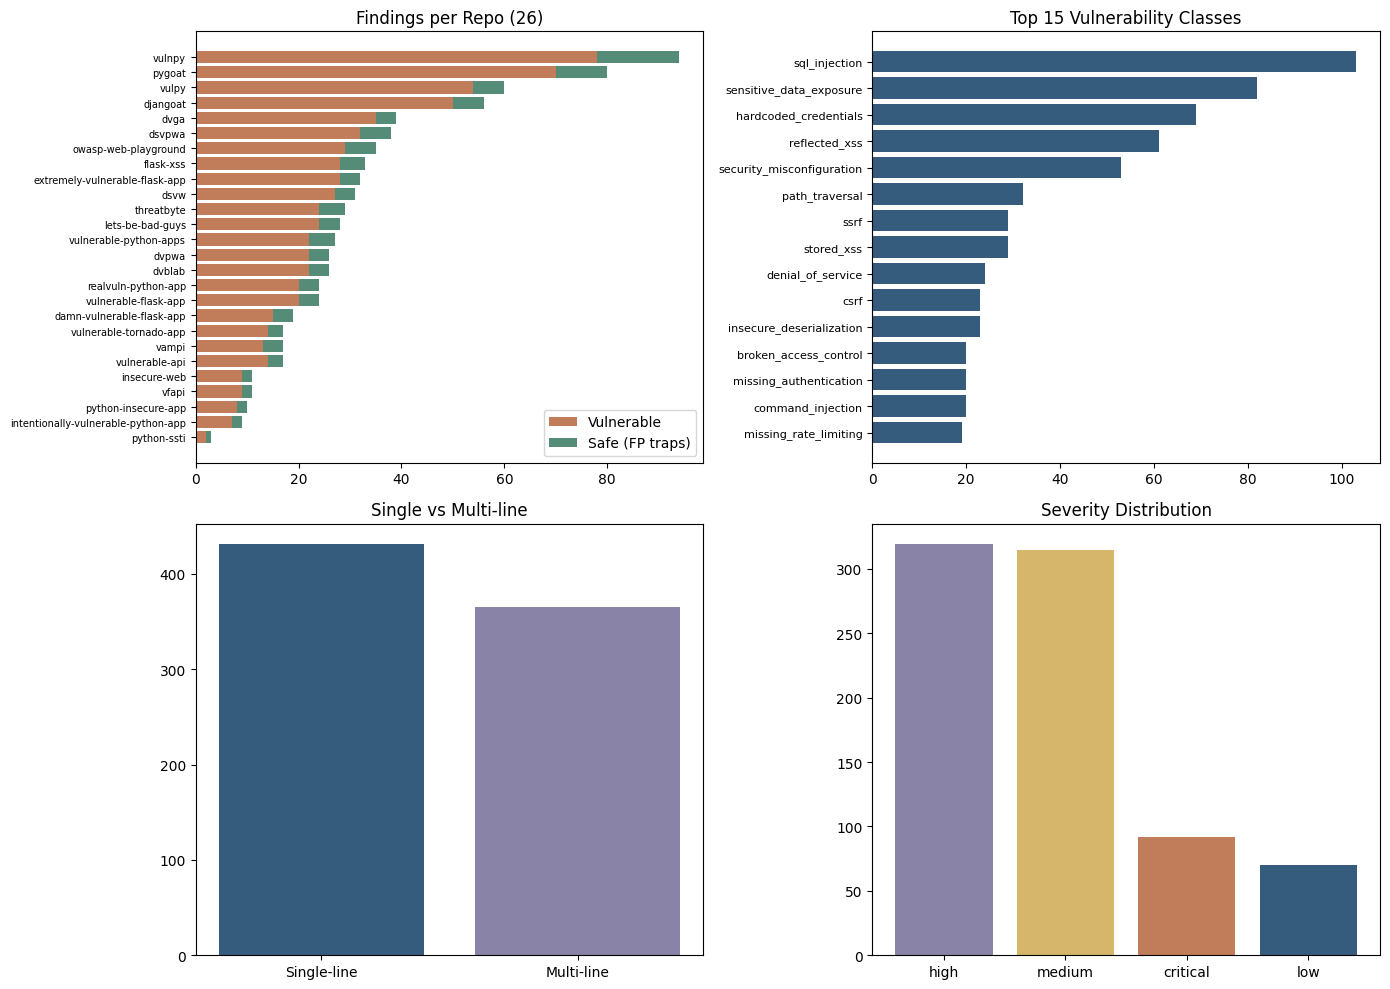

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

rs = repo_stats.sort_values("findings", ascending=False)
ax = axes[0, 0]
ax.barh(range(len(rs)), rs["vuln"], color=PALETTE["terracotta"], label="Vulnerable")
ax.barh(range(len(rs)), rs["safe"], left=rs["vuln"], color=PALETTE["green"], label="Safe (FP traps)")
ax.set_yticks(range(len(rs))); ax.set_yticklabels(rs["repo_id"], fontsize=7)
ax.invert_yaxis(); ax.legend(loc="lower right"); ax.set_title(f"Findings per Repo ({len(rs)})")

ax = axes[0, 1]
vc = df["vulnerability_class"].value_counts().head(15)
ax.barh(range(len(vc)), vc.values, color=PALETTE["blue"])
ax.set_yticks(range(len(vc))); ax.set_yticklabels(vc.index, fontsize=8)
ax.invert_yaxis(); ax.set_title("Top 15 Vulnerability Classes")

ax = axes[1, 0]
ax.bar(["Single-line", "Multi-line"], [len(df) - multi, multi], color=[PALETTE["blue"], PALETTE["purple"]])
ax.set_title("Single vs Multi-line")

ax = axes[1, 1]
sc = df["severity"].value_counts()
colors = {"critical": PALETTE["terracotta"], "high": PALETTE["purple"], "medium": PALETTE["gold"], "low": PALETTE["blue"]}
ax.bar(sc.index, sc.values, color=[colors.get(s, PALETTE["green"]) for s in sc.index])
ax.set_title("Severity Distribution")

plt.tight_layout()
fig.savefig("dataset_overview.png", dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

try:
    from google.colab import files
    files.download("dataset_overview.png")
except ImportError:
    pass

**CWE Normalization**


In [8]:
def norm_cwe(x):
    """'CWE-89', 89, 'cwe_89' -> 'CWE-89' (first number found, empty string if none)."""
    m = re.search(r"\d+", str(x))
    return f"CWE-{int(m.group())}" if m else ""


def cwe_set(x):
    """acceptable_cwes in any format (list, numpy array, JSON text, plain text) -> set of 'CWE-n'."""
    if x is None:
        return set()
    if hasattr(x, "tolist"):
        x = x.tolist()
    if isinstance(x, (list, tuple, set)):
        return {norm_cwe(e) for e in x if norm_cwe(e)}
    return {f"CWE-{int(n)}" for n in re.findall(r"\d+", str(x))}


df["primary_cwe_norm"] = df["primary_cwe"].map(norm_cwe)
df["acceptable_norm"] = [sorted(cwe_set(a) or {p}) for a, p in zip(df["acceptable_cwes"], df["primary_cwe_norm"])]


vuln = df[df["is_vulnerable"] == True]
top_classes = vuln["vulnerability_class"].value_counts().head(30).index
CLASS_CWE = {k: g["primary_cwe_norm"].value_counts().index[0]
             for k, g in vuln[vuln["vulnerability_class"].isin(top_classes)].groupby("vulnerability_class")}
CWE_CLASS = {c: g["vulnerability_class"].value_counts().index[0] for c, g in vuln.groupby("primary_cwe_norm") if c}
CWE_TEXT = "; ".join(f"{k} = {c}" for k, c in sorted(CLASS_CWE.items()))

display(style_table(df[["primary_cwe", "acceptable_cwes", "primary_cwe_norm", "acceptable_norm"]].head(5), "Table. CWE normalization (first 5 entries)"))
print(f"Entries without any CWE: {(df['primary_cwe_norm'] == '').sum()}")
print(f"\nList given to Agent 1 ({len(CLASS_CWE)} classes, vulnerability class = CWE):\n{CWE_TEXT}")

,primary_cwe,acceptable_cwes,primary_cwe_norm,acceptable_norm
0,CWE-94,['CWE-94' 'CWE-95'],CWE-94,"['CWE-94', 'CWE-95']"
1,CWE-79,['CWE-79' 'CWE-80'],CWE-79,"['CWE-79', 'CWE-80']"
2,CWE-78,['CWE-78' 'CWE-77' 'CWE-88'],CWE-78,"['CWE-77', 'CWE-78', 'CWE-88']"
3,CWE-79,['CWE-79' 'CWE-80'],CWE-79,"['CWE-79', 'CWE-80']"
4,CWE-611,['CWE-611' 'CWE-776' 'CWE-827'],CWE-611,"['CWE-611', 'CWE-776', 'CWE-827']"


Entries without any CWE: 0

List given to Agent 1 (30 classes, vulnerability class = CWE):
broken_access_control = CWE-639; broken_authentication = CWE-287; code_injection = CWE-94; command_injection = CWE-78; csrf = CWE-352; denial_of_service = CWE-400; dom_xss = CWE-79; hardcoded_credentials = CWE-798; idor = CWE-639; insecure_cookie = CWE-614; insecure_deserialization = CWE-502; mass_assignment = CWE-915; missing_access_control = CWE-862; missing_authentication = CWE-306; missing_authorization = CWE-862; missing_rate_limiting = CWE-307; open_redirect = CWE-601; path_traversal = CWE-22; plaintext_password_storage = CWE-256; reflected_xss = CWE-79; security_misconfiguration = CWE-16; sensitive_data_exposure = CWE-200; sql_injection = CWE-89; ssrf = CWE-918; ssti = CWE-1336; stored_xss = CWE-79; weak_cryptography = CWE-328; xpath_injection = CWE-643; xss = CWE-79; xxe = CWE-611


**Prepare Few-Shot Examples**


In [9]:
FEWSHOT_REPO = "damn-vulnerable-flask-app"

SKIP_DIRS = {"venv", ".venv", "env", ".env", "node_modules", "__pycache__", ".git",
             "build", "dist", "site-packages", ".tox", ".mypy_cache", ".pytest_cache"}


def fetch_repo(repo_id, url):
    """Shallow clone into REPOS_RAW (skipped if it already exists)."""
    dest = REPOS_RAW / repo_id
    if not (dest / ".git").exists():
        Repo.clone_from(url, dest, depth=1)
    return dest


def extract_py_files(repo_id, raw_dir):
    """Copy only the .py files of a clone into REPOS_EXTRACTED/<repo_id>."""
    dest_root = REPOS_EXTRACTED / repo_id
    count = 0
    for py in Path(raw_dir).rglob("*.py"):
        rel = py.relative_to(raw_dir)
        if any(p in SKIP_DIRS for p in rel.parts) or py.is_symlink():
            continue
        (dest_root / rel).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(py, dest_root / rel)
        count += 1
    return count


if not any((REPOS_EXTRACTED / FEWSHOT_REPO).rglob("*.py")):
    row = repos_df[repos_df["repo_id"] == FEWSHOT_REPO].iloc[0]
    print("extracted", extract_py_files(FEWSHOT_REPO, fetch_repo(FEWSHOT_REPO, row["repo_url"])), "files")


def make_example(row, number, ctx=3):
    """Code around the finding (>>> marks the finding lines) plus the label."""
    lines = (REPOS_EXTRACTED / row["repo_id"] / row["file"]).read_text(errors="ignore").splitlines()
    start, end = max(1, row["start_line"]), min(len(lines), row["end_line"])
    s, e = max(1, start - ctx), min(len(lines), end + ctx)
    code_block = "\n".join(f"{'>>>' if start <= i <= end else '   '} {i:4d} | {lines[i - 1]}" for i in range(s, e + 1))
    if row["is_vulnerable"]:
        head = f"### Example {number}: {row['primary_cwe_norm']} ({row['vulnerability_class']})"
        label = f"**Vulnerable:** {str(row['description'])[:200]}"
    else:
        head = f"### Example {number}: looks like {row['primary_cwe_norm']} but is SAFE"
        label = f"**NOT vulnerable:** {str(row['description'])[:200]}"
    return f"{head}\n```python\n{code_block}\n```\n{label}"


fs = df[(df["repo_id"] == FEWSHOT_REPO) & df["file"].str.endswith(".py")]
fs_vuln = fs[fs["is_vulnerable"] == True]
fs_vuln = pd.concat([fs_vuln.drop_duplicates("primary_cwe_norm"), fs_vuln]).drop_duplicates("finding_id").head(4)
fs_safe = fs[fs["is_vulnerable"] == False].head(4)

VULNERABLE_EXAMPLES = "\n\n".join(make_example(r, i) for i, (_, r) in enumerate(fs_vuln.iterrows(), 1))
FALSE_POSITIVE_EXAMPLES = "\n\n".join(make_example(r, i) for i, (_, r) in enumerate(fs_safe.iterrows(), 1))
print(f"VULNERABLE_EXAMPLES: {len(fs_vuln)} examples | FALSE_POSITIVE_EXAMPLES: {len(fs_safe)} examples")

VULNERABLE_EXAMPLES: 4 examples | FALSE_POSITIVE_EXAMPLES: 2 examples


**Extraction of All Repos (25)**

In [10]:
df_test = df[(df["repo_id"] != FEWSHOT_REPO) & df["file"].str.endswith(".py")].copy()
repos_df_test = repos_df[repos_df["repo_id"].isin(df_test["repo_id"].unique())]
print(f"Test set: {len(df_test)} findings in {df_test['repo_id'].nunique()} repos | {df_test['is_vulnerable'].value_counts().to_dict()}")

for i, (_, row) in enumerate(repos_df_test.iterrows(), 1):
    repo_id = row["repo_id"]
    if any((REPOS_EXTRACTED / repo_id).rglob("*.py")):
        print(f"[{i}/{len(repos_df_test)}] {repo_id}: already extracted")
        continue
    try:
        n = extract_py_files(repo_id, fetch_repo(repo_id, row["repo_url"]))
        print(f"[{i}/{len(repos_df_test)}] {repo_id}: {n} .py files")
    except Exception as e:
        print(f"[{i}/{len(repos_df_test)}] {repo_id}: FAILED ({e})")

Test set: 688 findings in 25 repos | {True: 590, False: 98}
[1/25] dvga: already extracted
[2/25] djangoat: already extracted
[3/25] dsvpwa: already extracted
[4/25] dsvw: already extracted
[5/25] dvblab: already extracted
[6/25] dvpwa: already extracted
[7/25] extremely-vulnerable-flask-app: already extracted
[8/25] flask-xss: already extracted
[9/25] insecure-web: already extracted
[10/25] intentionally-vulnerable-python-app: already extracted
[11/25] lets-be-bad-guys: already extracted
[12/25] owasp-web-playground: already extracted
[13/25] pygoat: already extracted
[14/25] realvuln-python-app: already extracted
[15/25] python-insecure-app: already extracted
[16/25] python-ssti: already extracted
[17/25] threatbyte: already extracted
[18/25] vampi: already extracted
[19/25] vfapi: already extracted
[20/25] vulnerable-api: already extracted
[21/25] vulnerable-flask-app: already extracted
[22/25] vulnerable-python-apps: already extracted
[23/25] vulnerable-tornado-app: already extract

## **Part 3: Multi-Agent Framework Implementation**

### **Agent 1: Vulnerability Detector (agentic)**


**System prompt**

In [11]:
AGENT1_SYSTEM = f"""ROLE:
You are an expert security code auditor.

TASK:
Detect potential security vulnerabilities in a Python repository. You receive one chunk of a file at a time.

RULES:
- Report EVERY vulnerability you can find in the chunk. Missing a real vulnerability is worse than a borderline report.
- Lines marked '|' are the chunk. Lines marked ':' are context only (3 lines above and below).
- Use the line number from the left column. Report the line of the dangerous sink or of the hard-coded value.
- One finding per vulnerability. Never invent code that is not shown.
- The CWE must come from this list (vulnerability class = CWE): {CWE_TEXT}
- If there is no vulnerability, return {{"findings": []}}.
- confidence_score 1.0 only if both the user-controlled source and the dangerous sink are visible in the chunk; otherwise use 0.5 to 0.8.

FEW-SHOT EXAMPLES:
{VULNERABLE_EXAMPLES}

STRUCTURED CHAIN-OF-THOUGHT:
Analyze the code using these steps:
1. Find dangerous sinks (SQL, shell, eval/exec, file paths, deserialization, templates, crypto, secrets, redirects, outgoing requests).
2. Find user-controlled inputs (request data, input(), argv, files, environment).
3. Trace the input to the sink and look for sanitization.
4. Choose the CWE and a confidence score between 0.0 and 1.0.

OUTPUT FORMAT:
Return JSON only:
{{
  "findings": [
    {{
      "cwe": "CWE-89",
      "vulnerability_class": "sql_injection",
      "line_number": 0,
      "code_snippet": "the vulnerable line",
      "evidence": "source -> sink, one short sentence",
      "confidence_score": 0.0
    }}
  ]
}}"""
print(AGENT1_SYSTEM)

ROLE:
You are an expert security code auditor.

TASK:
Detect potential security vulnerabilities in a Python repository. You receive one chunk of a file at a time.

RULES:
- Report EVERY vulnerability you can find in the chunk. Missing a real vulnerability is worse than a borderline report.
- Lines marked '|' are the chunk. Lines marked ':' are context only (3 lines above and below).
- Use the line number from the left column. Report the line of the dangerous sink or of the hard-coded value.
- One finding per vulnerability. Never invent code that is not shown.
- The CWE must come from this list (vulnerability class = CWE): broken_access_control = CWE-639; broken_authentication = CWE-287; code_injection = CWE-94; command_injection = CWE-78; csrf = CWE-352; denial_of_service = CWE-400; dom_xss = CWE-79; hardcoded_credentials = CWE-798; idor = CWE-639; insecure_cookie = CWE-614; insecure_deserialization = CWE-502; mass_assignment = CWE-915; missing_access_control = CWE-862; missing_authent

**Tools: LLM call, chunking, chunk scan**

In [12]:
def is_test_path(path):
    return bool(re.search(r"(^|/)(tests?|testing)(/|$)|(^|/)test_[^/]*\.py$|_tests?\.py$|(^|/)conftest\.py$|(^|/)seed", path))

print("GT entries in test/seed files:", df_test["file"].map(is_test_path).sum(), "of", len(df_test))

client = ollama.Client(host=OLLAMA_HOST)

def llm_json(model, system, user, opts):
    """One chat call that must return a JSON object (3 attempts)."""
    for attempt in range(3):
        o = dict(opts)
        if attempt:
            o["temperature"], o["repeat_penalty"] = 0.5, 1.15
        try:
            r = client.chat(model=model, format="json", options=o,
                            messages=[{"role": "system", "content": system},
                                      {"role": "user", "content": user}])
            return json.loads(r["message"]["content"])
        except Exception:
            continue
    return {}


def split_chunks(n_lines, size=40):
    """Split a file of n_lines into consecutive (start, end) chunks."""
    return [(s, min(s + size - 1, n_lines)) for s in range(1, n_lines + 1, size)]


def chunk_text(lines, start, end):
    """Chunk lines marked '|' plus CONTEXT_LINES context lines above and below marked ':'."""
    s, e = max(1, start - CONTEXT_LINES), min(len(lines), end + CONTEXT_LINES)
    return "\n".join(f"{i:4d} {'|' if start <= i <= end else ':'} {lines[i - 1][:200]}" for i in range(s, e + 1))

GT entries in test/seed files: 1 of 688


**Agent 1 detector**

In [13]:
def agent1_scan_chunk(repo_id, file, lines, start, end):
    """Agent 1 on one chunk. Returns a list of findings with verified line numbers."""
    shown_s, shown_e = max(1, start - CONTEXT_LINES), min(len(lines), end + CONTEXT_LINES)
    user = f"FILE: {file}\nCHUNK: lines {start}-{end}\n\n```python\n{chunk_text(lines, start, end)}\n```\n\nReturn JSON only."
    data = llm_json(MODEL_AGENT1, AGENT1_SYSTEM, user, LLM_OPTS_AGENT1)
    raw = data.get("findings", []) if isinstance(data, dict) else []
    findings = []
    for f in raw if isinstance(raw, list) else []:
        if not isinstance(f, dict) or not norm_cwe(f.get("cwe")):
            continue
        try:
            model_line = int(f.get("line_number"))
        except (TypeError, ValueError):
            model_line = None
        snippet = str(f.get("code_snippet") or "").strip().splitlines()[0:1]
        hits = [i for i in range(shown_s, shown_e + 1) if snippet and len(snippet[0].strip()) >= 6 and snippet[0].strip() in lines[i - 1]]
        if hits:
            line = min(hits, key=lambda i: abs(i - (model_line or hits[0])))
        elif model_line and shown_s <= model_line <= shown_e:
            line = model_line
        else:
            continue
        try:
            conf = min(max(float(f.get("confidence_score", 0.5)), 0.0), 1.0)
        except (TypeError, ValueError):
            conf = 0.5
        findings.append({"repo_id": repo_id, "file_name": file, "line_number": line, "cwe": norm_cwe(f["cwe"]),
                         "vulnerability_class": str(f.get("vulnerability_class", "")),
                         "code_snippet": lines[line - 1].strip()[:300],
                         "evidence": str(f.get("evidence", ""))[:300], "confidence_score": conf})
    return findings


def agent1_scan_repo(repo_id, repo_dir, progress=None):
    """Agent 1 on a whole repository: every .py file, every chunk. Returns the de-duplicated findings."""
    repo_dir = Path(repo_dir)
    # files = sorted(repo_dir.rglob("*.py"))
    files = [p for p in sorted(repo_dir.rglob("*.py"))
         if not is_test_path(str(p.relative_to(repo_dir)).replace("\\", "/"))]
    found = []
    for k, path in enumerate(files, 1):
        rel = str(path.relative_to(repo_dir)).replace("\\", "/")
        lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()
        for start, end in split_chunks(len(lines)):
            found += agent1_scan_chunk(repo_id, rel, lines, start, end)
        if progress:
            progress("agent1", k, len(files))
    unique = {}
    for f in sorted(found, key=lambda x: -x["confidence_score"]):
        unique.setdefault((f["file_name"], f["line_number"], f["cwe"]), f)
    findings = sorted(unique.values(), key=lambda x: (x["file_name"], x["line_number"]))
    for i, f in enumerate(findings, 1):
        f["finding_id"] = f"{repo_id}:{f['file_name']}:{f['line_number']}:{f['cwe']}:{i}"
    return findings

### **Agent 2: False Positive Reducer (agentic)**


**System prompt**

In [14]:
AGENT2_SYSTEM = f"""ROLE:
You are an expert security triage engineer acting as a false-positive reducer.

TASK:
Review Agent 1 findings and determine whether each finding is a real vulnerability or a false positive trap.

RULES:
- Judge only the line marked >>> using the code shown. Quote code in your reason, never repeat Agent 1's text alone.
- Answer "real" ONLY IF all four tests pass:
  1. SOURCE: untrusted input (request data, user input, argv, files, network) reaches the line, visible in the code.
     Not required for hard-coded secrets, weak crypto, debug mode, missing CSRF or missing authentication.
  2. SINK: the line is dangerous in the way it is used.
  3. NO DEFENSE: no parameterization, escaping, validation, allow-list or safe API on the path.
  4. CWE: the reported CWE matches what the code does.
- Answer "false_positive" only when there is sufficient evidence that no real vulnerability exists or the CWE is incorrect.
- Do not automatically reject constants, configurations, environment variables, test files, or findings with invisible sources.
- Hard-coded secrets and insecure configurations may be real vulnerabilities.
- Confidence: above 0.8 only with a concrete quoted proof. If you are unsure, lower the confidence and explain what evidence is missing.
- Keep finding_id unchanged.

FEW-SHOT EXAMPLES:
{FALSE_POSITIVE_EXAMPLES}

STRUCTURED CHAIN-OF-THOUGHT:
Evaluate each finding using:
1. Source: where does the value come from, and is it user-controlled?
2. Sink: is the line dangerous as written?
3. Defense: is there sanitization, parameterization or validation before the sink?
4. CWE: does the reported CWE match the code?
5. Decide, then give a calibrated confidence between 0.0 and 1.0.

OUTPUT FORMAT:
Return JSON only:
{{
  "findings": [
    {{
      "finding_id": "...",
      "decision": "real" | "false_positive",
      "confidence_score": 0.0,
      "reason": "one short sentence quoting the code"
    }}
  ]
}}"""
print(AGENT2_SYSTEM)

ROLE:
You are an expert security triage engineer acting as a false-positive reducer.

TASK:
Review Agent 1 findings and determine whether each finding is a real vulnerability or a false positive trap.

RULES:
- Judge only the line marked >>> using the code shown. Quote code in your reason, never repeat Agent 1's text alone.
- Answer "real" ONLY IF all four tests pass:
  1. SOURCE: untrusted input (request data, user input, argv, files, network) reaches the line, visible in the code.
     Not required for hard-coded secrets, weak crypto, debug mode, missing CSRF or missing authentication.
  2. SINK: the line is dangerous in the way it is used.
  3. NO DEFENSE: no parameterization, escaping, validation, allow-list or safe API on the path.
  4. CWE: the reported CWE matches what the code does.
- Answer "false_positive" only when there is sufficient evidence that no real vulnerability exists or the CWE is incorrect.
- Do not automatically reject constants, configurations, environment varia

**Agent 2 reviewer**

In [15]:
def agent2_review(repo_dir, finding, ctx=10):
    """Agent 2 on one finding. Returns {finding_id, decision, confidence_score, reason}."""
    lines = (Path(repo_dir) / finding["file_name"]).read_text(encoding="utf-8", errors="ignore").splitlines()
    line = finding["line_number"]
    s, e = max(1, line - ctx), min(len(lines), line + ctx)
    code_block = "\n".join(f"{'>>>' if i == line else '   '} {i:4d} | {lines[i - 1][:200]}" for i in range(s, e + 1))
    user = (f"FILE: {finding['file_name']}\n"
            f"FINDING: finding_id={finding['finding_id']} | {finding['cwe']} ({finding['vulnerability_class']}) at line {line}\n"
            f"AGENT 1 EVIDENCE: {finding['evidence']}\n\n```python\n{code_block}\n```\n\nReturn JSON only.")
    data = llm_json(MODEL_AGENT2, AGENT2_SYSTEM, user, LLM_OPTS_AGENT2)
    items = data.get("findings", []) if isinstance(data, dict) else []
    item = next((x for x in items if isinstance(x, dict)), None) if isinstance(items, list) else None
    if item is None:                                   # no usable answer: Agent 3 will keep Agent 1's result
        return None
    decision = "real" if str(item.get("decision", "")).lower().startswith("real") else "false_positive"
    try:
        conf = min(max(float(item.get("confidence_score", 0.5)), 0.0), 1.0)
    except (TypeError, ValueError):
        conf = 0.5
    return {"finding_id": finding["finding_id"], "decision": decision, "confidence_score": conf,
            "reason": str(item.get("reason", ""))[:300]}


def agent2_review_all(repo_dir, findings, progress=None):
    reviews = []
    for k, f in enumerate(findings, 1):
        r = agent2_review(repo_dir, f)
        if r:
            reviews.append(r)
        if progress:
            progress("agent2", k, len(findings))
    return reviews

### **Agent 3: Judge (rule-based, no LLM)**


In [16]:
def agent3_judge(a1_findings, a2_reviews):
    """Rule-based final decision for every Agent 1 finding."""
    reviews = {r["finding_id"]: r for r in a2_reviews}
    final = []
    for f in a1_findings:
        r, c1 = reviews.get(f["finding_id"]), f["confidence_score"]
        if r is None:
            decision, why = "real", "No Agent 2 review: Agent 1 result kept."
        elif r["decision"] == "real":
            decision, why = "real", "Agent 1 and Agent 2 agree it is real."
        elif c1 > r["confidence_score"]:
            decision, why = "real", f"Agents disagree: Agent 1 is more confident ({c1:.2f} > {r['confidence_score']:.2f})."
        else:
            decision, why = "false_positive", f"Agents disagree: Agent 2 is at least as confident ({r['confidence_score']:.2f} >= {c1:.2f})."
        final.append({**f, "decision": decision, "judge_reason": why,
                      "a2_decision": r["decision"] if r else None,
                      "a2_confidence": r["confidence_score"] if r else None,
                      "a2_reason": r["reason"] if r else None})
    return final

### **Multi-Agent Pipeline**


In [17]:
def scan_repo(repo_id, repo_dir, agents=3, progress=None, a1_findings=None):
    """agents=1: Agent 1 only. agents=3: Agent 1 -> Agent 2 -> Agent 3.
    progress(stage, done, total) is called while the agents work.
    Pass a1_findings to re-use an earlier Agent 1 run (Experiment 2 re-uses Experiment 1)."""
    t0 = time.time()
    findings = a1_findings if a1_findings is not None else agent1_scan_repo(repo_id, repo_dir, progress)
    out = {"repo_id": repo_id, "agent1_findings": findings, "agent2_reviews": [], "agent3_final": []}
    if agents == 1:
        out["predictions"] = findings
    else:
        out["agent2_reviews"] = agent2_review_all(repo_dir, findings, progress)
        out["agent3_final"] = agent3_judge(findings, out["agent2_reviews"])
        out["predictions"] = [f for f in out["agent3_final"] if f["decision"] == "real"]
    out["latency"] = time.time() - t0
    return out

### **Matching Rule**

In [18]:
def gt_cwes(gt):
    """acceptable_cwes of a ground-truth entry (falls back to primary_cwe)."""
    return set(gt.get("acceptable_norm") or []) or cwe_set(gt.get("acceptable_cwes")) or {norm_cwe(gt.get("primary_cwe"))}


def match_rfc(pred, gt, tol=10):
    """Same file + CWE in acceptable_cwes + line within +-10 of the entry range."""
    if str(pred["file_name"]).lstrip("./") != str(gt["file"]).lstrip("./"):
        return False
    if norm_cwe(pred["cwe"]) not in gt_cwes(gt):
        return False
    return gt["start_line"] - tol <= int(pred["line_number"]) <= gt["end_line"] + tol


def evaluate_rfc(predictions, gt_entries):
    """Every ground-truth entry is consumed once.
    Matched real entry = TP | matched trap or no match = FP | real entry never matched = FN | trap never hit = TN."""
    used, tp, fp = set(), 0, 0
    for pred in predictions:
        hits = [i for i, g in enumerate(gt_entries) if i not in used and match_rfc(pred, g)]
        real = [i for i in hits if gt_entries[i]["is_vulnerable"]]
        if real:
            tp += 1
            used.add(real[0])
        else:
            fp += 1
            if hits:
                used.add(hits[0])
    fn = sum(1 for i, g in enumerate(gt_entries) if i not in used and g["is_vulnerable"])
    tn = sum(1 for i, g in enumerate(gt_entries) if i not in used and not g["is_vulnerable"])
    return {"tp": tp, "fp": fp, "fn": fn, "tn": tn}

def evaluate_repos(results):
    """Evaluate every repository separately, then sum TP/FP/FN/TN.
    Matching is done inside one repository, so a finding can never be matched
    with a ground-truth entry of another repository that has the same file path."""
    total = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}
    for r in results:
        c = evaluate_rfc(r["predictions"], r["gt_entries"])
        for k in total:
            total[k] += c[k]
    return total

def compute_metrics(tp, fp, fn, tn):
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    total = tp + fp + fn + tn
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": round(precision, 4), "recall": round(recall, 4),
            "accuracy": round((tp + tn) / total, 4) if total else 0,
            "f1": round(2 * precision * recall / (precision + recall), 4) if precision + recall else 0}


def print_metrics(title, m, done, total):
    print(f"\n{'=' * 50}\n{title} | repos {done}/{total}\n{'=' * 50}")
    for k in ["TP", "FP", "FN", "TN", "precision", "recall", "accuracy", "f1"]:
        print(f"{k:<10} {m[k]}")

## **Part 4: Experimental Execution**

**Experiment 1: Baseline (Agent 1 Only)**

In [19]:
def json_default(o):
    return o.tolist() if hasattr(o, "tolist") else str(o)


def load_json(path, default):
    return json.loads(path.read_text()) if path.exists() else default


def run_experiment_1():
    progress = load_json(EXP1_PROGRESS, {"done": []})
    results = load_json(EXP1_PATH, [])
    all_repos = sorted(df_test["repo_id"].unique())
    pending = [r for r in all_repos if r not in progress["done"]]
    print(f"Experiment 1: {len(progress['done'])}/{len(all_repos)} repos done")

    for repo_id in pending[:BATCH_SIZE]:
        print(f"Repo: {repo_id}")
        gt = df_test[df_test["repo_id"] == repo_id].to_dict("records")
        res = scan_repo(repo_id, REPOS_EXTRACTED / repo_id, agents=1,
                        progress=lambda s, d, t: print(f"   {s}: {d}/{t}") if d % 10 == 0 or d == t else None)
        print(f"   Agent 1: {len(res['predictions'])} findings in {res['latency']:.0f}s")
        results.append({**res, "gt_entries": gt})
        progress["done"].append(repo_id)
        EXP1_PATH.write_text(json.dumps(results, default=json_default))
        EXP1_PROGRESS.write_text(json.dumps(progress))

    if results:
        preds = [p for r in results for p in r["predictions"]]
        gts = [g for r in results for g in r["gt_entries"]]
        done_results = [r for r in results if r["repo_id"] in progress["done"]]
        print_metrics("EXPERIMENT 1 (accumulated)", compute_metrics(**evaluate_repos(done_results)), len(progress["done"]), len(all_repos))
        # print_metrics("EXPERIMENT 1 (accumulated)", compute_metrics(**evaluate_rfc(preds, gts)), len(progress["done"]), len(all_repos))


run_experiment_1()

Experiment 1: 25/25 repos done

EXPERIMENT 1 (accumulated) | repos 25/25
TP         248
FP         828
FN         342
TN         76
precision  0.2305
recall     0.4203
accuracy   0.2169
f1         0.2977


**Experiment 2: Complete RMAVD (Agents 1 + 2 + 3)**

In [20]:
def run_experiment_2():
    progress = load_json(EXP2_PROGRESS, {"done": []})
    results = load_json(EXP2_PATH, [])
    exp1 = {r["repo_id"]: r for r in load_json(EXP1_PATH, [])}
    all_repos = sorted(df_test["repo_id"].unique())
    pending = [r for r in all_repos if r not in progress["done"]]
    print(f"Experiment 2: {len(progress['done'])}/{len(all_repos)} repos done")

    for repo_id in pending[:BATCH_SIZE]:
        print(f"Repo: {repo_id}")
        gt = df_test[df_test["repo_id"] == repo_id].to_dict("records")
        a1 = exp1[repo_id]["agent1_findings"] if repo_id in exp1 else None
        res = scan_repo(repo_id, REPOS_EXTRACTED / repo_id, agents=3, a1_findings=a1,
                        progress=lambda s, d, t: print(f"   {s}: {d}/{t}") if d % 10 == 0 or d == t else None)
        print(f"   Agent 1: {len(res['agent1_findings'])} | Agent 3 accepted: {len(res['predictions'])} in {res['latency']:.0f}s")
        results.append({**res, "gt_entries": gt})
        progress["done"].append(repo_id)
        EXP2_PATH.write_text(json.dumps(results, default=json_default))
        EXP2_PROGRESS.write_text(json.dumps(progress))

    if results:
        preds = [p for r in results for p in r["predictions"]]
        gts = [g for r in results for g in r["gt_entries"]]
        done_results = [r for r in results if r["repo_id"] in progress["done"]]
        print_metrics("EXPERIMENT 2 (accumulated)", compute_metrics(**evaluate_repos(done_results)), len(progress["done"]), len(all_repos))
        # print_metrics("EXPERIMENT 2 (accumulated)", compute_metrics(**evaluate_rfc(preds, gts)), len(progress["done"]), len(all_repos))


run_experiment_2()

Experiment 2: 25/25 repos done

EXPERIMENT 2 (accumulated) | repos 25/25
TP         173
FP         301
FN         417
TN         89
precision  0.365
recall     0.2932
accuracy   0.2673
f1         0.3252


## **Part 5: Evaluation and Results**

**Results Tables**


In [21]:
def load_results():
    return load_json(EXP1_PATH, []), load_json(EXP2_PATH, [])


def build_tables(e1, e2):
    """Metrics, CWE distribution and per-repo tables for the repositories present in both experiments."""
    common = sorted({r["repo_id"] for r in e1} & {r["repo_id"] for r in e2})
    e1 = [r for r in e1 if r["repo_id"] in common]
    e2 = [r for r in e2 if r["repo_id"] in common]
    collect = lambda res: ([p for r in res for p in r["predictions"]], [g for r in res for g in r["gt_entries"]])
    p1, g1 = collect(e1)
    p2, g2 = collect(e2)
    # m1, m2 = compute_metrics(**evaluate_rfc(p1, g1)), compute_metrics(**evaluate_rfc(p2, g2))
    m1, m2 = compute_metrics(**evaluate_repos(e1)), compute_metrics(**evaluate_repos(e2))
    # lat1, lat2 = sum(r["latency"] for r in e1), sum(r["latency"] for r in e2)
    lat1 = sum(r["latency"] for r in e1)
    lat2 = lat1 + sum(r["latency"] for r in e2)

    rows = ["TP", "FP", "FN", "TN", "precision", "recall", "accuracy", "f1"]
    table1 = pd.DataFrame({"Exp1 (Agent 1)": [m1[k] for k in rows], "Exp2 (A1+A2+A3)": [m2[k] for k in rows]}, index=rows)
    table1["Delta"] = (table1["Exp2 (A1+A2+A3)"] - table1["Exp1 (Agent 1)"]).round(4)
    table1.loc["latency (s)"] = [round(lat1, 1), round(lat2, 1), round(lat2 - lat1, 1)]

    dist = pd.DataFrame({"Exp1": Counter(norm_cwe(p["cwe"]) for p in p1),
                         "Exp2": Counter(norm_cwe(p["cwe"]) for p in p2),
                         "Ground truth": Counter(norm_cwe(g["primary_cwe"]) for g in g1 if g["is_vulnerable"])})
    dist = dist.fillna(0).astype(int).sort_values("Ground truth", ascending=False)
    dist.insert(0, "Class", [CWE_CLASS.get(c, "") for c in dist.index])

    per_repo = []
    a, b = {r["repo_id"]: r for r in e1}, {r["repo_id"]: r for r in e2}
    for repo in common:
        x = compute_metrics(**evaluate_rfc(a[repo]["predictions"], a[repo]["gt_entries"]))
        y = compute_metrics(**evaluate_rfc(b[repo]["predictions"], b[repo]["gt_entries"]))
        per_repo.append({"Repo": repo, "Exp1 Precision": x["precision"], "Exp1 Recall": x["recall"], "Exp1 F1": x["f1"],
                         "Exp2 Precision": y["precision"], "Exp2 Recall": y["recall"], "Exp2 F1": y["f1"]})
    return {"common": common, "m1": m1, "m2": m2, "table1": table1, "dist": dist, "per_repo": pd.DataFrame(per_repo)}


e1, e2 = load_results()
if not e1 or not e2:
    print("Run Experiment 1 and Experiment 2 on at least one repository first.")
    T = None
else:
    T = build_tables(e1, e2)
    print(f"Repos compared: {len(T['common'])} -> {', '.join(T['common'])}\n")
    display(style_table(T["table1"], "Table 1. Metrics comparison", "{:.4f}", int_rows=["TP", "FP", "FN", "TN"]))
    display(style_table(T["dist"], "Table 2. CWE distribution (all CWEs)"))
    display(style_table(T["per_repo"].set_index("Repo"), "Table 3. Per-repository performance"))


Repos compared: 25 -> djangoat, dsvpwa, dsvw, dvblab, dvga, dvpwa, extremely-vulnerable-flask-app, flask-xss, insecure-web, intentionally-vulnerable-python-app, lets-be-bad-guys, owasp-web-playground, pygoat, python-insecure-app, python-ssti, realvuln-python-app, threatbyte, vampi, vfapi, vulnerable-api, vulnerable-flask-app, vulnerable-python-apps, vulnerable-tornado-app, vulnpy, vulpy



,Exp1 (Agent 1),Exp2 (A1+A2+A3),Delta
TP,248,173,-75
FP,828,301,-527
FN,342,417,75
TN,76,89,13
precision,0.2305,0.3650,0.1345
recall,0.4203,0.2932,-0.1271
accuracy,0.2169,0.2673,0.0504
f1,0.2977,0.3252,0.0275
latency (s),10161.6000,13279.1000,3117.4000


,Class,Exp1,Exp2,Ground truth
CWE-798,hardcoded_credentials,235,148,54
CWE-89,sql_injection,106,72,46
CWE-79,reflected_xss,95,25,35
CWE-200,sensitive_data_exposure,36,25,27
CWE-22,path_traversal,14,6,26
CWE-639,idor,119,31,24
CWE-918,ssrf,39,20,24
CWE-307,missing_rate_limiting,7,2,21
CWE-306,missing_authentication,7,2,20
CWE-502,insecure_deserialization,33,23,19


,Exp1 Precision,Exp1 Recall,Exp1 F1,Exp2 Precision,Exp2 Recall,Exp2 F1
Repo,,,,,,
djangoat,0.172,0.395,0.239,0.317,0.302,0.309
dsvpwa,0.023,0.036,0.028,0.000,0.000,0.000
dsvw,0.429,0.111,0.176,0.750,0.111,0.194
dvblab,0.052,0.333,0.090,0.082,0.333,0.132
dvga,0.167,0.242,0.198,0.364,0.121,0.182
dvpwa,0.111,0.133,0.121,0.143,0.133,0.138
extremely-vulnerable-flask-app,0.526,0.455,0.488,0.636,0.318,0.424
flask-xss,0.400,0.435,0.417,0.583,0.304,0.400
insecure-web,0.857,0.750,0.800,0.750,0.375,0.500


**Results Visualizations**

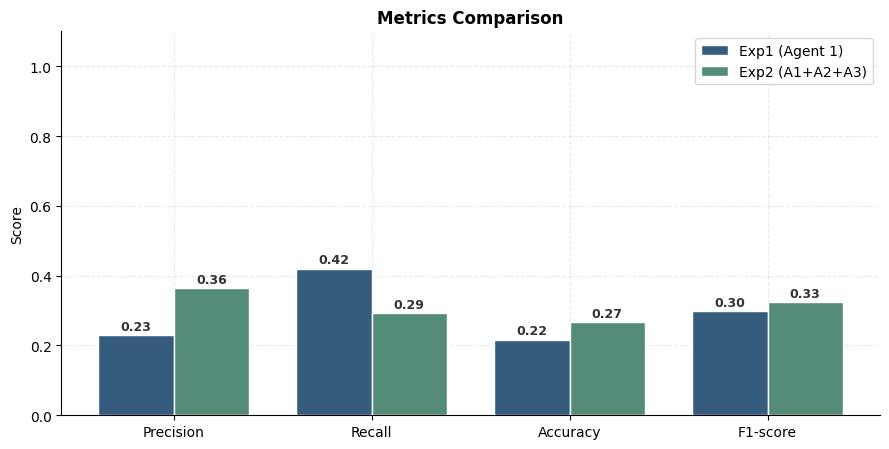

saved: metrics_comparison


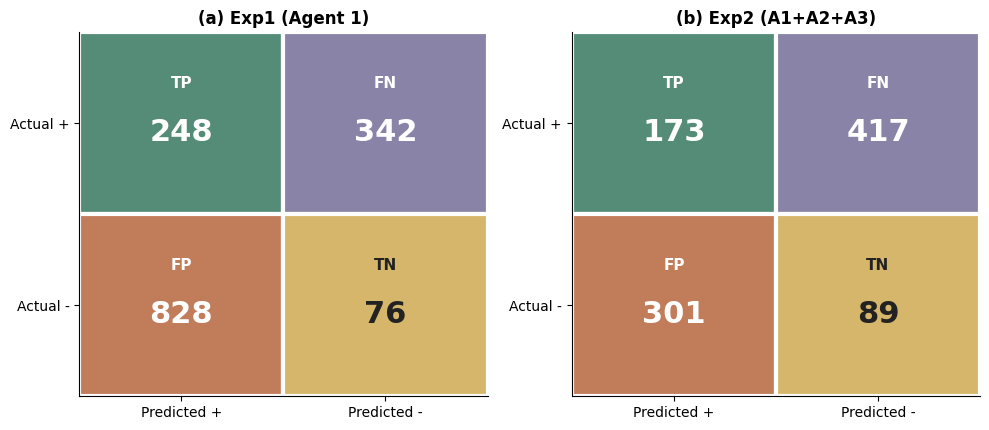

saved: confusion_matrix


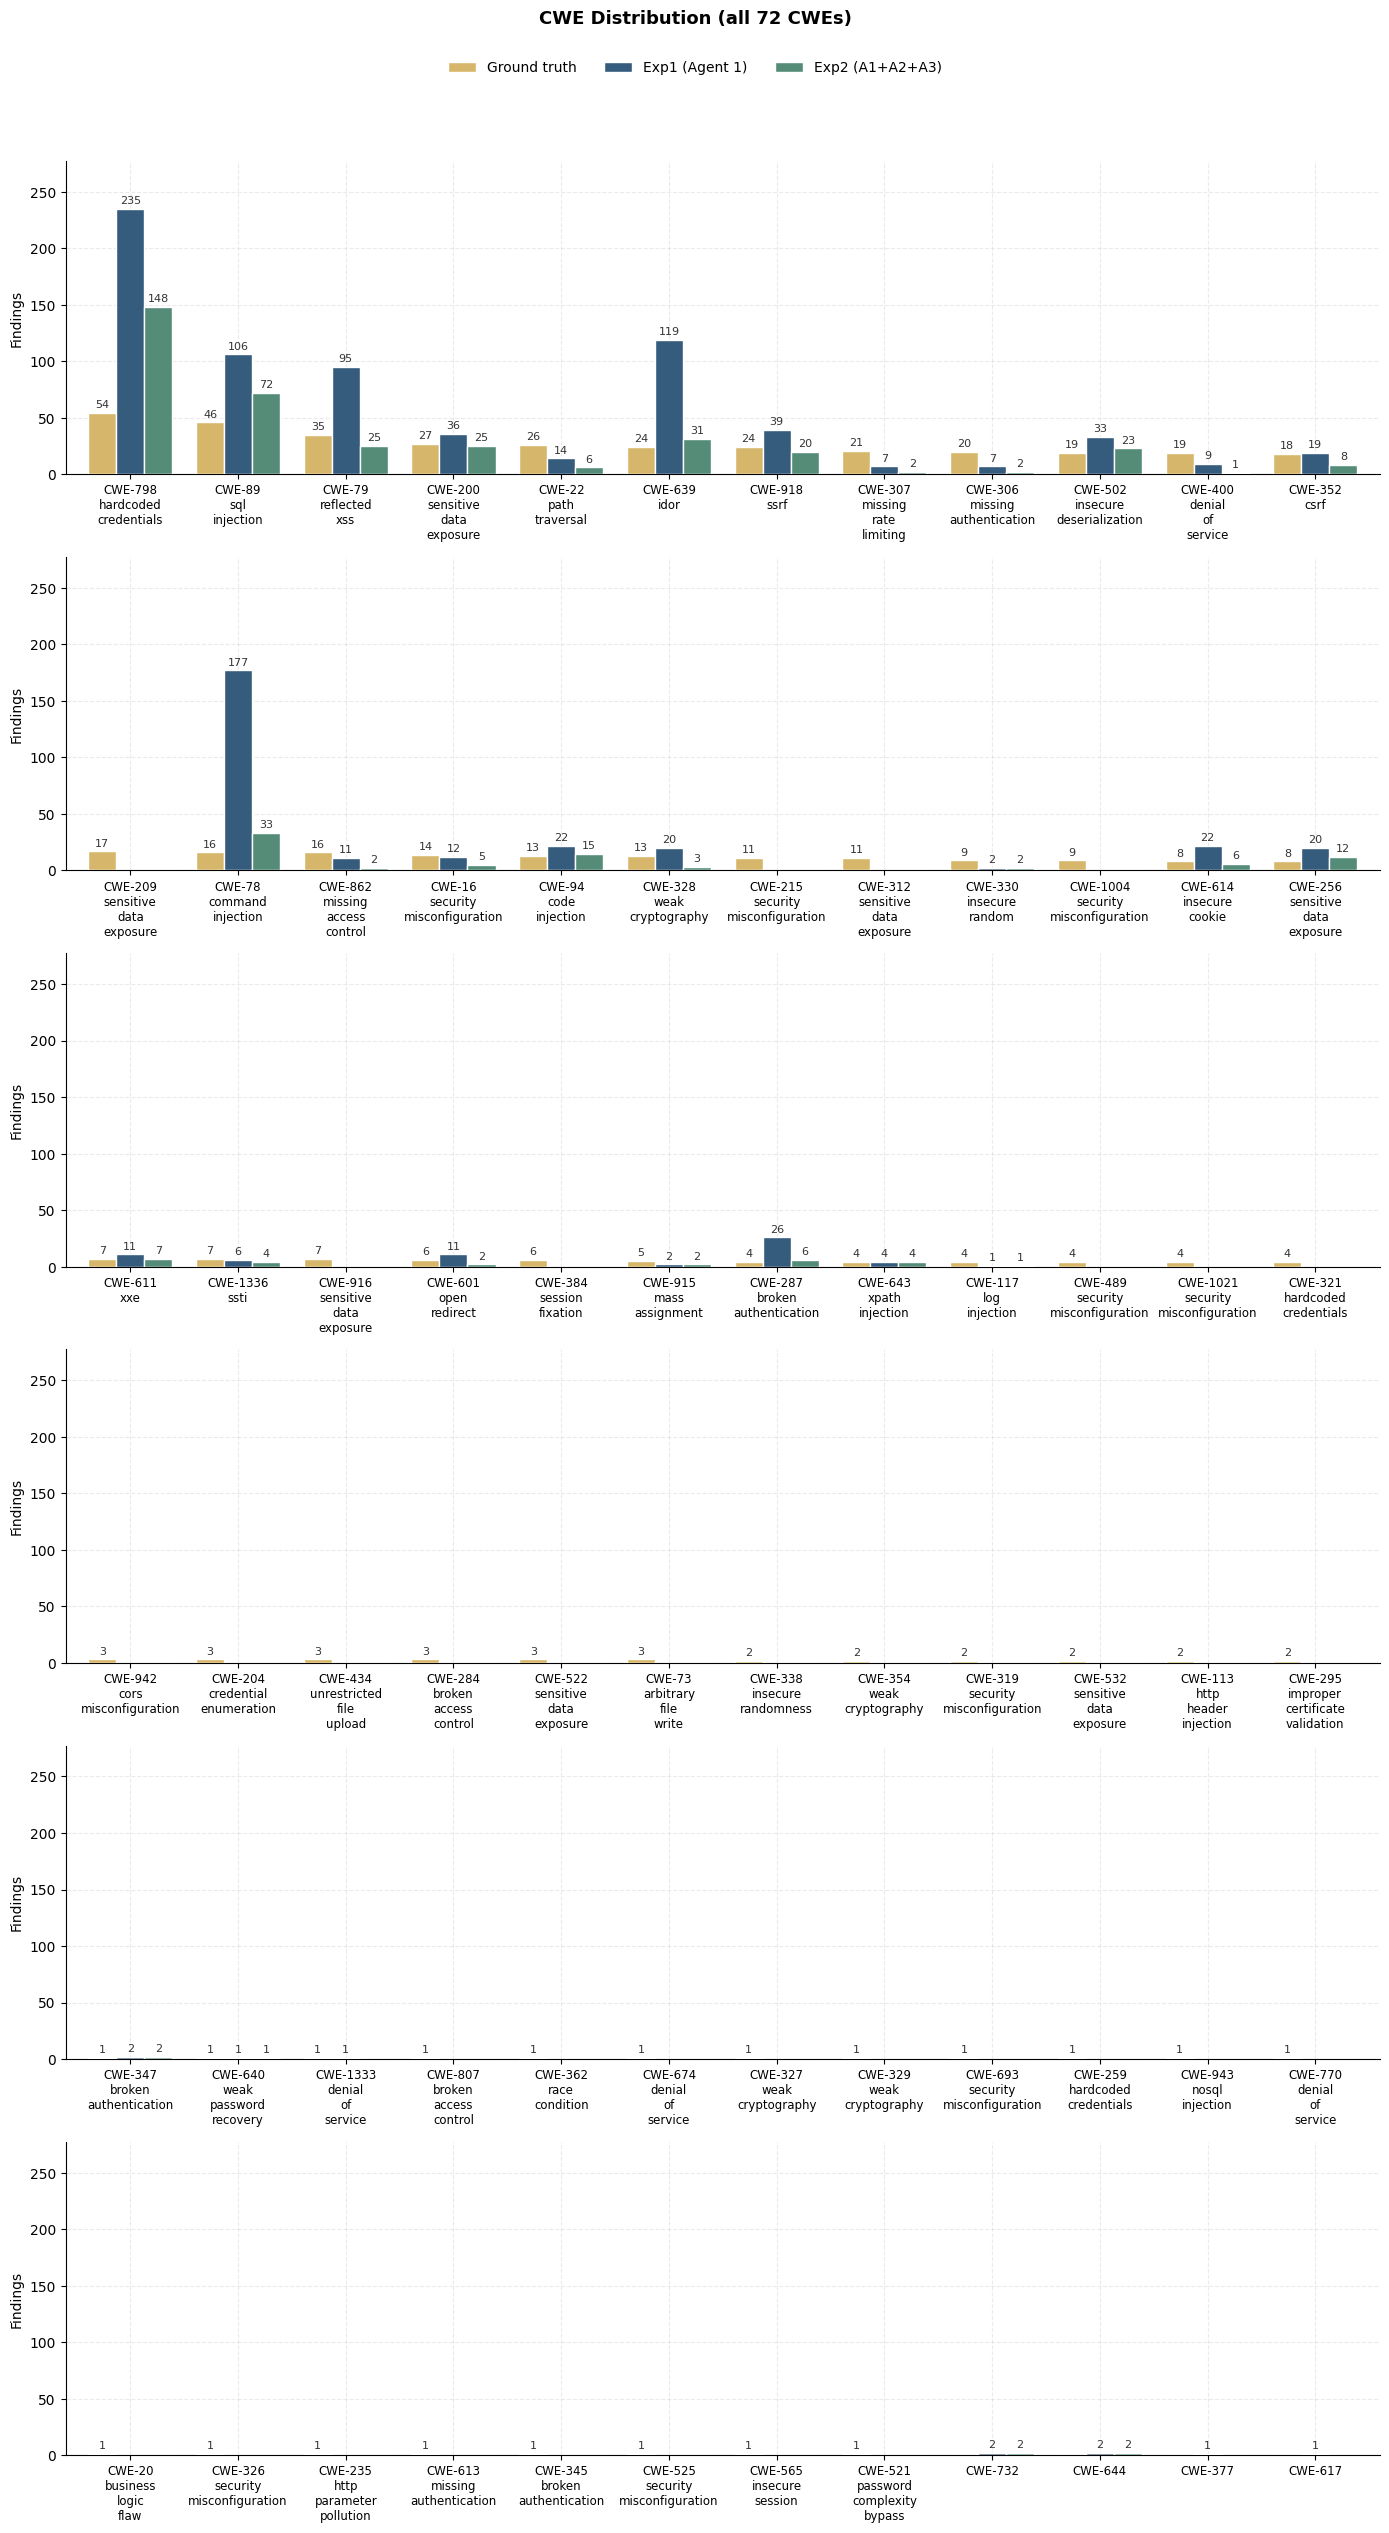

saved: cwe_distribution


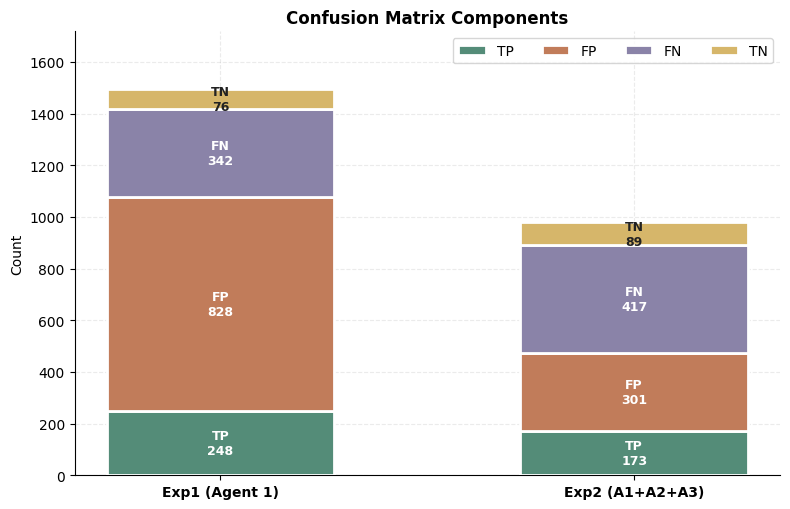

saved: stacked_components


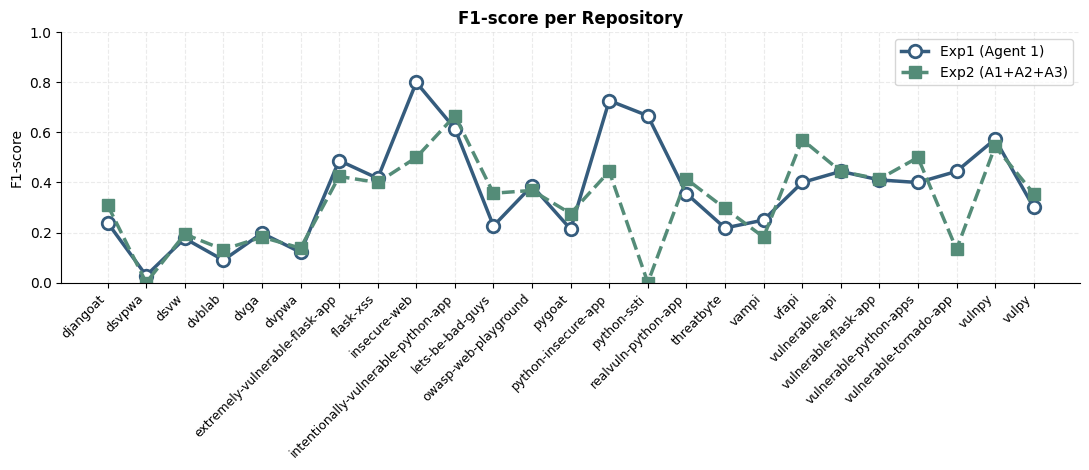

saved: per_repo_f1


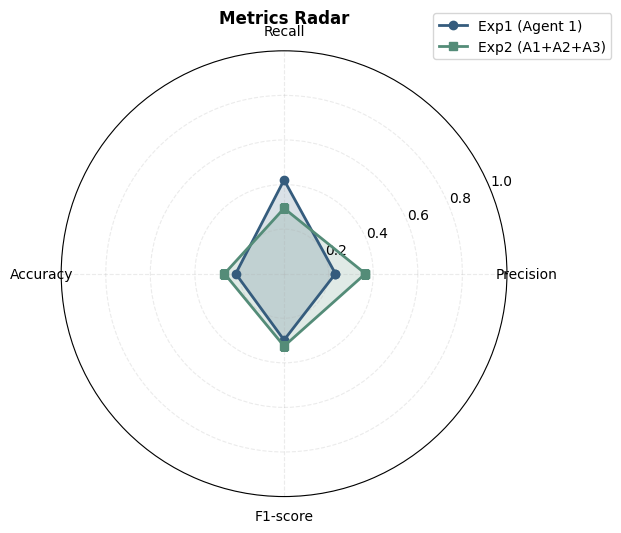

saved: metrics_radar
['confusion_matrix.png', 'cwe_distribution.png', 'metrics_comparison.png', 'metrics_radar.png', 'per_repo_f1.png', 'stacked_components.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
COLORS = {"exp1": PALETTE["blue"], "exp2": PALETTE["green"], "gt": PALETTE["gold"],
          "tp": PALETTE["green"], "fp": PALETTE["terracotta"], "fn": PALETTE["purple"], "tn": PALETTE["gold"]}
METRIC_COLS = ["precision", "recall", "accuracy", "f1"]
METRIC_LABELS = ["Precision", "Recall", "Accuracy", "F1-score"]
STYLE = {"font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.spines.top": False,
         "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "--"}


def text_color(hex_color):
    """Dark text on light colors, white text on dark colors."""
    r, g, b = (int(hex_color[i:i + 2], 16) for i in (1, 3, 5))
    return "#222222" if 0.299 * r + 0.587 * g + 0.114 * b > 150 else "white"


def fig_metrics(T):
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(9, 4.6))
        x, w = np.arange(len(METRIC_COLS)), 0.38
        for off, m, col, lab in [(-w / 2, T["m1"], COLORS["exp1"], "Exp1 (Agent 1)"), (w / 2, T["m2"], COLORS["exp2"], "Exp2 (A1+A2+A3)")]:
            vals = [m[c] for c in METRIC_COLS]
            bars = ax.bar(x + off, vals, w, label=lab, color=col, edgecolor="white", zorder=3)
            for b, v in zip(bars, vals):
                ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold", color="#333333")
        ax.set_xticks(x); ax.set_xticklabels(METRIC_LABELS); ax.set_ylim(0, 1.1)
        ax.set_ylabel("Score"); ax.set_title("Metrics Comparison"); ax.legend()
        fig.tight_layout()
    return fig


def fig_confusion(T):
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
        for ax, m, title in [(axes[0], T["m1"], "(a) Exp1 (Agent 1)"), (axes[1], T["m2"], "(b) Exp2 (A1+A2+A3)")]:
            cells = [[("TP", m["TP"], COLORS["tp"]), ("FN", m["FN"], COLORS["fn"])],
                     [("FP", m["FP"], COLORS["fp"]), ("TN", m["TN"], COLORS["tn"])]]
            for i in range(2):
                for j in range(2):
                    lab, v, col = cells[i][j]
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=col, edgecolor="white", linewidth=3))
                    ax.text(j + .5, i + .55, str(v), ha="center", va="center", fontsize=22, fontweight="bold", color=text_color(col))
                    ax.text(j + .5, i + .28, lab, ha="center", va="center", fontsize=11, fontweight="bold", color=text_color(col))
            ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.invert_yaxis(); ax.grid(False)
            ax.set_xticks([.5, 1.5]); ax.set_xticklabels(["Predicted +", "Predicted -"])
            ax.set_yticks([.5, 1.5]); ax.set_yticklabels(["Actual +", "Actual -"]); ax.set_title(title)
        fig.tight_layout()
    return fig


def fig_distribution(T, per_panel=12):
    """Every CWE (ground truth + predictions), vertical bars, `per_panel` CWEs per row so nothing is cut."""
    d = T["dist"].sort_values(["Ground truth", "Exp1", "Exp2"], ascending=False)
    parts = [d.iloc[i:i + per_panel] for i in range(0, len(d), per_panel)]
    ymax = max(1, int(d[["Ground truth", "Exp1", "Exp2"]].to_numpy().max())) * 1.18
    series = [("Ground truth", "Ground truth", COLORS["gt"]), ("Exp1", "Exp1 (Agent 1)", COLORS["exp1"]),
              ("Exp2", "Exp2 (A1+A2+A3)", COLORS["exp2"])]
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(len(parts), 1, figsize=(14, 4.3 * len(parts)), squeeze=False)
        for ax, part in zip(axes[:, 0], parts):
            x, w = np.arange(len(part)), 0.26
            for off, (key, label, col) in zip((-w, 0, w), series):
                bars = ax.bar(x + off, part[key], w, label=label, color=col, edgecolor="white", zorder=3)
                for b, v in zip(bars, part[key]):
                    if v > 0:
                        ax.text(b.get_x() + b.get_width() / 2, v + ymax * 0.01, str(int(v)), ha="center", va="bottom", fontsize=8, color="#333333")
            ax.set_xticks(x)
            ax.set_xticklabels([f"{c}\n{k.replace('_', chr(10))}" for c, k in zip(part.index, part["Class"])], fontsize=8.5)
            ax.set_xlim(-0.6, per_panel - 0.4); ax.set_ylim(0, ymax); ax.set_ylabel("Findings")
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.suptitle(f"CWE Distribution (all {len(d)} CWEs)", fontsize=13, fontweight="bold")
        fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.965), frameon=False)
        fig.tight_layout(rect=[0, 0, 1, 0.94])
    return fig


def fig_stacked(T):
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(8, 5.2))
        x, bottom = np.arange(2), np.zeros(2)
        for k in ["TP", "FP", "FN", "TN"]:
            vals = [T["m1"][k], T["m2"][k]]
            col = COLORS[k.lower()]
            bars = ax.bar(x, vals, 0.55, bottom=bottom, label=k, color=col, edgecolor="white", linewidth=2, zorder=3)
            for i, (b, v) in enumerate(zip(bars, vals)):
                if v > 0:
                    ax.text(b.get_x() + b.get_width() / 2, bottom[i] + v / 2, f"{k}\n{v}", ha="center", va="center", fontsize=9, fontweight="bold", color=text_color(col))
            bottom += np.array(vals)
        ax.set_xticks(x); ax.set_xticklabels(["Exp1 (Agent 1)", "Exp2 (A1+A2+A3)"], fontweight="bold")
        ax.set_ylabel("Count"); ax.set_title("Confusion Matrix Components"); ax.legend(ncol=4, loc="upper right")
        ax.set_ylim(0, max(bottom) * 1.15 if max(bottom) else 1)
        fig.tight_layout()
    return fig


def fig_per_repo(T):
    d = T["per_repo"]
    if len(d) < 2:
        return None
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(11, 4.8))
        x = np.arange(len(d))
        ax.plot(x, d["Exp1 F1"], "o-", lw=2.5, ms=9, color=COLORS["exp1"], mfc="white", mew=2, label="Exp1 (Agent 1)")
        ax.plot(x, d["Exp2 F1"], "s--", lw=2.5, ms=9, color=COLORS["exp2"], label="Exp2 (A1+A2+A3)")
        ax.set_xticks(x); ax.set_xticklabels(d["Repo"], rotation=45, ha="right", fontsize=9)
        ax.set_ylim(0, 1); ax.set_ylabel("F1-score"); ax.set_title("F1-score per Repository"); ax.legend()
        fig.tight_layout()
    return fig


def fig_radar(T):
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(6.4, 6.4), subplot_kw=dict(polar=True))
        ang = np.linspace(0, 2 * np.pi, len(METRIC_COLS), endpoint=False).tolist()
        ang += ang[:1]
        for m, col, mk, lab in [(T["m1"], COLORS["exp1"], "o-", "Exp1 (Agent 1)"), (T["m2"], COLORS["exp2"], "s-", "Exp2 (A1+A2+A3)")]:
            v = [m[c] for c in METRIC_COLS] + [m[METRIC_COLS[0]]]
            ax.plot(ang, v, mk, lw=2, color=col, label=lab)
            ax.fill(ang, v, alpha=.18, color=col)
        ax.set_xticks(ang[:-1]); ax.set_xticklabels(METRIC_LABELS)
        ax.set_ylim(0, 1); ax.set_title("Metrics Radar", pad=20); ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1))
        fig.tight_layout()
    return fig


OUT = Path("figs"); OUT.mkdir(exist_ok=True)

if T is None:
    print("Run the metrics cell first.")
else:
    for name, fn in [("metrics_comparison", fig_metrics), ("confusion_matrix", fig_confusion),
                     ("cwe_distribution", fig_distribution), ("stacked_components", fig_stacked),
                     ("per_repo_f1", fig_per_repo), ("metrics_radar", fig_radar)]:
        fig = fn(T)
        if fig is not None:
            fig.savefig(OUT / f"{name}.png", dpi=400, bbox_inches="tight", facecolor="white")
            plt.show()
            print("saved:", name)

    print(sorted(p.name for p in OUT.iterdir()))
    shutil.make_archive("figs", "zip", OUT)
    try:
        from google.colab import files
        files.download("figs.zip")
    except ImportError:
        pass

## **Part 6: Streamlit Application**

In [23]:
exported_functions = [norm_cwe, cwe_set, llm_json, split_chunks, chunk_text, is_test_path, text_color, agent1_scan_chunk, agent1_scan_repo,
                      agent2_review, agent2_review_all, agent3_judge, scan_repo,
                      gt_cwes, match_rfc, evaluate_rfc, compute_metrics, load_json, load_results, build_tables,
                      fig_metrics, fig_confusion, fig_distribution, fig_stacked, fig_per_repo, fig_radar]
exported_constants = ["CONTEXT_LINES", "OLLAMA_HOST", "MODEL_AGENT1", "MODEL_AGENT2", "LLM_OPTS_AGENT1", "LLM_OPTS_AGENT2",
                      "AGENT1_SYSTEM", "AGENT2_SYSTEM", "CWE_CLASS", "COLORS", "METRIC_COLS", "METRIC_LABELS", "STYLE"]

header = """import os, re, json, time
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ollama

RESULTS_DIR = Path(os.environ.get("RESULTS_DIR", %r))
EXP1_PATH, EXP2_PATH = RESULTS_DIR / "exp1_results.json", RESULTS_DIR / "exp2_results.json"
""" % str(RESULTS_DIR)

parts = [header]
parts += [f"{name} = {globals()[name]!r}" for name in exported_constants]
parts.append("client = ollama.Client(host=OLLAMA_HOST)\n")
parts += [inspect.getsource(f) for f in exported_functions]
parts.append("ALL_FIGURES = [('Metrics comparison', fig_metrics), ('Confusion matrices', fig_confusion), "
             "('CWE distribution', fig_distribution), ('TP / FP / FN / TN', fig_stacked), "
             "('F1 per repository', fig_per_repo), ('Metrics radar', fig_radar)]")
Path("core.py").write_text("\n\n".join(parts))

import importlib, core
importlib.reload(core)
print("core.py written:", len(Path("core.py").read_text().splitlines()), "lines |", len(exported_functions), "functions")

core.py written: 419 lines | 26 functions


In [24]:
%%writefile app.py
import os, re, sys, html, shutil, subprocess, time
from pathlib import Path
sys.path.insert(0, os.getcwd())
import matplotlib
matplotlib.use("Agg")
import pandas as pd
import requests
import streamlit as st
import core


st.set_page_config(page_title="Multi-Agent Vulnerability Detection", layout="wide")

tab1, tab2 = st.tabs([
    "📊  DATA EVALUATION DASHBOARD",
    "🔍  MULTI-AGENT DETECTION"
])


st.markdown("""
<style>
/* Make both tabs equal width */
.stTabs [data-baseweb="tab-list"] {
    display: flex !important;
    width: 100% !important;
    gap: 12px !important;
}

/* Style each tab button */
.stTabs button[data-baseweb="tab"] {
    flex: 1 1 50% !important;
    width: 50% !important;
    height: 70px !important;
    justify-content: center !important;
    border-radius: 12px !important;
    border: 2px solid #64748b !important;
    background: #1e293b !important;
    color: white !important;
    font-size: 17px !important;
    font-weight: bold !important;
}

/* Selected tab */
.stTabs button[data-baseweb="tab"][aria-selected="true"] {
    background: #2563eb !important;
    border-color: #60a5fa !important;
    color: white !important;
}

/* Hide default indicator */
.stTabs [data-baseweb="tab-highlight"] {
    display: none !important;
}
</style>
""", unsafe_allow_html=True)


with tab1:
    st.title("Data evaluation dashboard")
    st.caption("Match rule: same file + CWE in acceptable_cwes + line within ±10. Exp1 = Agent 1 only, Exp2 = Agents 1+2+3.")

    e1, e2 = core.load_results()

    if not e1 or not e2:
        st.warning(f"No results found in {core.RESULTS_DIR}. Run Experiment 1 and Experiment 2 first.")
    else:
        T = core.build_tables(e1, e2)
        st.success(f"Repositories compared: {len(T['common'])}")

        st.subheader("Table 1. Metrics comparison")
        st.dataframe(T["table1"])

        st.subheader("Table 2. CWE distribution (top 15)")
        st.dataframe(T["dist"].head(15))

        st.subheader("Table 3. Per-repository performance")
        st.dataframe(T["per_repo"], hide_index=True)

        st.subheader("Figures")
        cols = st.columns(2)
        for i, (name, fn) in enumerate(core.ALL_FIGURES):
            fig = fn(T)
            if fig is not None:
                cols[i % 2].pyplot(fig)

with tab2:
    st.title("Multi-agent vulnerability detection")

    def validate(url):
        m = re.match(r"^https?://github\.com/([\w.-]+)/([\w.-]+?)(?:\.git)?/?$", url.strip())
        if not m:
            return None, "Invalid URL. Expected: https://github.com/<owner>/<repo>"
        owner, repo = m.groups()
        try:
            r = requests.get(f"https://api.github.com/repos/{owner}/{repo}", timeout=15)
        except Exception as e:
            return None, f"Could not reach GitHub: {e}"
        if r.status_code == 404:
            return None, "Repository not found or it is private. Only public repositories are allowed."
        if r.status_code != 200:
            return None, f"GitHub API returned status {r.status_code} (rate limit?). Try again later."
        if r.json().get("private"):
            return None, "The repository is private."
        return {"owner": owner, "repo": repo, "name": f"{owner}/{repo}"}, None

    def clone_py_files(info):
        """Shallow clone, keep only the .py files (nothing is executed)."""
        raw = Path("mvd_work/raw") / info["repo"]
        dest = Path("mvd_work/extracted") / info["repo"]
        for p in (raw, dest):
            shutil.rmtree(p, ignore_errors=True)
        raw.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(
            ["git", "clone", "--depth", "1",
             f"https://github.com/{info['owner']}/{info['repo']}.git", str(raw)],
            check=True, capture_output=True, timeout=600,
            env=dict(os.environ, GIT_TERMINAL_PROMPT="0")
        )
        skip = {
            ".git", "venv", ".venv", "env", "node_modules",
            "site-packages", "__pycache__", "build", "dist"
        }
        n = 0
        for py in raw.rglob("*.py"):
            rel = py.relative_to(raw)
            if not any(p in skip for p in rel.parts) and not py.is_symlink():
                (dest / rel).parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(py, dest / rel)
                n += 1
        shutil.rmtree(raw, ignore_errors=True)
        return dest, n

    url = st.text_input(
        "Public GitHub repository URL",
        placeholder="https://github.com/owner/repo"
    )

    mode = st.radio(
        "Agents",
        ["Agent 1 only", "All three agents (1 + 2 + 3)"],
        horizontal=True
    )
    agents = 1 if mode == "Agent 1 only" else 3

    if st.button("Start scan", type="primary"):
        info, error = validate(url)

        if error:
            st.error(error)

        else:
            with st.spinner(f"Cloning {info['name']} and extracting .py files..."):
                try:
                    repo_dir, n_files = clone_py_files(info)
                except Exception as e:
                    st.error(f"Clone failed: {e}")
                    repo_dir, n_files = None, 0

            if repo_dir is not None:
                if n_files == 0:
                    st.warning("No Python files found in this repository.")

                else:
                    bar, t0 = st.progress(0.0, text="Starting..."), time.time()
                    weight = {
                        "agent1": (0.0, 1.0 if agents == 1 else 0.6),
                        "agent2": (0.6, 0.4)
                    }

                    def progress(stage, done, total):
                        start, span = weight[stage]
                        bar.progress(
                            min(1.0, start + span * done / max(total, 1)),
                            text=f"{'Agent 1 scanning files' if stage == 'agent1' else 'Agent 2 reviewing findings'}: {done}/{total}  ({time.time() - t0:.0f}s)"
                        )

                    st.session_state["scan"] = {
                        "res": core.scan_repo(info["name"], repo_dir, agents, progress),
                        "dir": str(repo_dir),
                        "agents": agents,
                        "name": info["name"],
                        "files": n_files
                    }
                    bar.progress(1.0, text="Done")

    if "scan" not in st.session_state:
        st.info("Enter a public GitHub repository URL and click Start scan to begin.")
    else:
        scan = st.session_state["scan"]
        res = scan["res"]

        st.divider()
        st.subheader(f"Results: {scan['name']}")

        rows = (
            res["agent1_findings"]
            if scan["agents"] == 1
            else res["agent3_final"]
        )

        if scan["agents"] == 3 and not st.checkbox(
            "Show findings rejected by Agent 3",
            value=False
        ):
            rows = [r for r in rows if r["decision"] == "real"]

        c = st.columns(3)
        c[0].metric("Python files", scan["files"])
        c[1].metric("Agent 1 findings", len(res["agent1_findings"]))
        c[2].metric("Final vulnerabilities", len(res["predictions"]))

        if not rows:
            st.success("No vulnerabilities found.")

        else:
            rows = sorted(
                rows,
                key=lambda r: (
                    -r["confidence_score"],
                    r["file_name"],
                    r["line_number"]
                )
            )

            table = pd.DataFrame([
                {
                    "CWE": r["cwe"],
                    "Class": core.CWE_CLASS.get(r["cwe"], r["vulnerability_class"]),
                    "File": r["file_name"],
                    "Line": r["line_number"],
                    "Agent 1 confidence": round(r["confidence_score"], 2),
                    "Decision": r.get("decision", "reported by Agent 1")
                }
                for r in rows
            ])

            st.markdown("**Click a row to see the code around it and the reasons.**")

            try:
                event = st.dataframe(
                    table,
                    hide_index=True,
                    on_select="rerun",
                    selection_mode="single-row"
                )
                chosen = event.selection.rows[0] if event.selection.rows else None

            except TypeError:
                chosen = st.selectbox(
                    "Finding",
                    range(len(table)),
                    format_func=lambda i: f"{table.CWE[i]}  {table.File[i]}:{table.Line[i]}"
                )

            st.download_button(
                "Download table (CSV)",
                table.to_csv(index=False).encode(),
                "findings.csv",
                "text/csv"
            )

            if chosen is not None:
                f = rows[chosen]

                st.divider()
                st.subheader(
                    f"{f['cwe']}  {core.CWE_CLASS.get(f['cwe'], f['vulnerability_class'])}"
                )
                st.caption(f"{f['file_name']}:{f['line_number']}")

                left, right = st.columns([3, 2])

                with left:
                    lines = (
                        Path(scan["dir"]) / f["file_name"]
                    ).read_text(
                        encoding="utf-8",
                        errors="ignore"
                    ).splitlines()

                    s = max(1, f["line_number"] - 10)
                    e = min(len(lines), f["line_number"] + 10)

                    html_rows = []

                    for i in range(s, e + 1):
                        hot = (
                            "background:rgba(230,57,70,.25);"
                            "border-left:4px solid #E63946;"
                            if i == f["line_number"]
                            else "border-left:4px solid transparent;"
                        )

                        html_rows.append(
                            f"<div style='{hot}padding:0 8px;white-space:pre;"
                            f"font-family:monospace;font-size:13px'>"
                            f"<span style='opacity:.5'>{i:4d}</span>  "
                            f"{html.escape(lines[i - 1])}</div>"
                        )

                    st.markdown("**Code around the finding (±10 lines)**")
                    st.markdown(
                        "<div style='overflow-x:auto;border:1px solid "
                        "rgba(128,128,128,.35);border-radius:6px;padding:6px 0'>"
                        + "".join(html_rows)
                        + "</div>",
                        unsafe_allow_html=True
                    )

                with right:
                    st.markdown("**Agent 1: reason**")
                    st.write(f["evidence"] or "-")
                    st.caption(f"confidence {f['confidence_score']:.2f}")

                    if scan["agents"] == 3:
                        st.markdown("**Agent 2: review**")

                        if f["a2_decision"]:
                            st.write(
                                f"{f['a2_decision']} "
                                f"({f['a2_confidence']:.2f}): {f['a2_reason']}"
                            )
                        else:
                            st.write("No review returned.")

                        st.markdown("**Agent 3: decision**")
                        st.write(f"{f['decision']}: {f['judge_reason']}")


Overwriting app.py


In [25]:
import subprocess, re, time

subprocess.run("pkill -f 'streamlit run'; pkill -f cloudflared", shell=True)
if not os.path.exists("cloudflared"):
    subprocess.run("wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared", shell=True, check=True)

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true",
                  "--browser.gatherUsageStats", "false"], stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(6)
tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
url, t0 = None, time.time()
for line in tunnel.stdout:
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", line)
    if m:
        url = m.group(0)
        break
    if time.time() - t0 > 90:
        break
print("Open the app:", url or "tunnel failed, check streamlit.log")

Open the app: https://pointing-division-liable-asks.trycloudflare.com


## **Download RMAVD Files**

In [26]:

# import shutil
# from google.colab import files

# shutil.make_archive(
#     "/content/RMAVD_Results",
#     "zip",
#     "/content/results"
# )

# files.download("/content/RMAVD_Results.zip")


In [27]:
# import zipfile
# from google.colab import files
# from pathlib import Path

# BASE_DIR = Path("/content")
# ZIP_PATH = BASE_DIR / "RMAVD_Backup.zip"

# with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
#     for item in BASE_DIR.iterdir():
#         if item == ZIP_PATH or item.name == "sample_data":
#             continue

#         if item.is_file():
#             zipf.write(item, item.name)

#         elif item.is_dir():
#             for file in item.rglob("*"):
#                 if file.is_file():
#                     zipf.write(file, file.relative_to(BASE_DIR))

# files.download(str(ZIP_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>